In [1]:
   # 1. 定义问题
   # a 导入类库
import numpy as np
from numpy import arange
from matplotlib import pyplot
import pandas as pd
from pandas import read_csv
from pandas import set_option
from pandas.plotting import scatter_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split,KFold,cross_val_score,GridSearchCV
from sklearn.linear_model import LinearRegression,Lasso,ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor,ExtraTreesRegressor,AdaBoostRegressor
from sklearn.metrics import mean_squared_error

   # b 导入数据集
filename = '/home/GUO_Zimeng/coding/Large_language_model_learning_project/ML/dataset/house.csv'
names = ['CRIM','ZN','INDUS','CHAS','NOX','RM','AGE','DIS','RAD','TAX','PRTATIO','B','LSTAT','MEDV']
data = pd.read_csv(filename, names=names, sep='\s+')

In [ ]:

   # 2. 理解数据
# 数据维度
print('数据维度：',data.shape)
print(data.dtypes)


数据维度： (506, 14)
CRIM       float64
ZN         float64
INDUS      float64
CHAS         int64
NOX        float64
RM         float64
AGE        float64
DIS        float64
RAD          int64
TAX        float64
PRTATIO    float64
B          float64
LSTAT      float64
MEDV       float64
dtype: object


In [3]:
# 查看最开始的30条记录
set_option('display.width',120)
print(data.head(30))

       CRIM    ZN  INDUS  CHAS    NOX     RM    AGE     DIS  RAD    TAX  PRTATIO       B  LSTAT  MEDV
0   0.00632  18.0   2.31     0  0.538  6.575   65.2  4.0900    1  296.0     15.3  396.90   4.98  24.0
1   0.02731   0.0   7.07     0  0.469  6.421   78.9  4.9671    2  242.0     17.8  396.90   9.14  21.6
2   0.02729   0.0   7.07     0  0.469  7.185   61.1  4.9671    2  242.0     17.8  392.83   4.03  34.7
3   0.03237   0.0   2.18     0  0.458  6.998   45.8  6.0622    3  222.0     18.7  394.63   2.94  33.4
4   0.06905   0.0   2.18     0  0.458  7.147   54.2  6.0622    3  222.0     18.7  396.90   5.33  36.2
5   0.02985   0.0   2.18     0  0.458  6.430   58.7  6.0622    3  222.0     18.7  394.12   5.21  28.7
6   0.08829  12.5   7.87     0  0.524  6.012   66.6  5.5605    5  311.0     15.2  395.60  12.43  22.9
7   0.14455  12.5   7.87     0  0.524  6.172   96.1  5.9505    5  311.0     15.2  396.90  19.15  27.1
8   0.21124  12.5   7.87     0  0.524  5.631  100.0  6.0821    5  311.0     15.2  

In [4]:
# 描述性统计信息
print(data.describe().round(1))

        CRIM     ZN  INDUS   CHAS    NOX     RM    AGE    DIS    RAD    TAX  PRTATIO      B  LSTAT   MEDV
count  506.0  506.0  506.0  506.0  506.0  506.0  506.0  506.0  506.0  506.0    506.0  506.0  506.0  506.0
mean     3.6   11.4   11.1    0.1    0.6    6.3   68.6    3.8    9.5  408.2     18.5  356.7   12.7   22.5
std      8.6   23.3    6.9    0.3    0.1    0.7   28.1    2.1    8.7  168.5      2.2   91.3    7.1    9.2
min      0.0    0.0    0.5    0.0    0.4    3.6    2.9    1.1    1.0  187.0     12.6    0.3    1.7    5.0
25%      0.1    0.0    5.2    0.0    0.4    5.9   45.0    2.1    4.0  279.0     17.4  375.4    7.0   17.0
50%      0.3    0.0    9.7    0.0    0.5    6.2   77.5    3.2    5.0  330.0     19.0  391.4   11.4   21.2
75%      3.7   12.5   18.1    0.0    0.6    6.6   94.1    5.2   24.0  666.0     20.2  396.2   17.0   25.0
max     89.0  100.0   27.7    1.0    0.9    8.8  100.0   12.1   24.0  711.0     22.0  396.9   38.0   50.0


In [5]:
# 关联关系
print(data.corr(method='pearson').round(2))

         CRIM    ZN  INDUS  CHAS   NOX    RM   AGE   DIS   RAD   TAX  PRTATIO     B  LSTAT  MEDV
CRIM     1.00 -0.20   0.41 -0.06  0.42 -0.22  0.35 -0.38  0.63  0.58     0.29 -0.39   0.46 -0.39
ZN      -0.20  1.00  -0.53 -0.04 -0.52  0.31 -0.57  0.66 -0.31 -0.31    -0.39  0.18  -0.41  0.36
INDUS    0.41 -0.53   1.00  0.06  0.76 -0.39  0.64 -0.71  0.60  0.72     0.38 -0.36   0.60 -0.48
CHAS    -0.06 -0.04   0.06  1.00  0.09  0.09  0.09 -0.10 -0.01 -0.04    -0.12  0.05  -0.05  0.18
NOX      0.42 -0.52   0.76  0.09  1.00 -0.30  0.73 -0.77  0.61  0.67     0.19 -0.38   0.59 -0.43
RM      -0.22  0.31  -0.39  0.09 -0.30  1.00 -0.24  0.21 -0.21 -0.29    -0.36  0.13  -0.61  0.70
AGE      0.35 -0.57   0.64  0.09  0.73 -0.24  1.00 -0.75  0.46  0.51     0.26 -0.27   0.60 -0.38
DIS     -0.38  0.66  -0.71 -0.10 -0.77  0.21 -0.75  1.00 -0.49 -0.53    -0.23  0.29  -0.50  0.25
RAD      0.63 -0.31   0.60 -0.01  0.61 -0.21  0.46 -0.49  1.00  0.91     0.46 -0.44   0.49 -0.38
TAX      0.58 -0.31   0.72 -0.

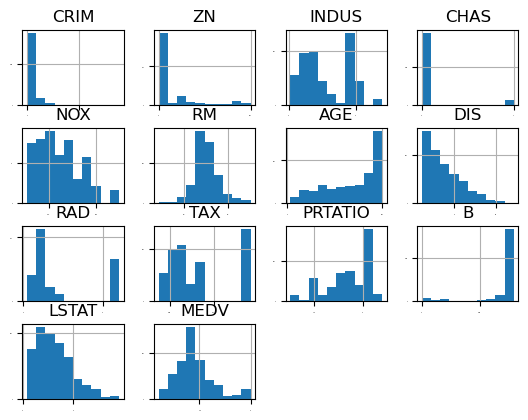

In [6]:
# 直方图
data.hist(sharex=False, sharey=False, xlabelsize=1,ylabelsize=1)
pyplot.show()

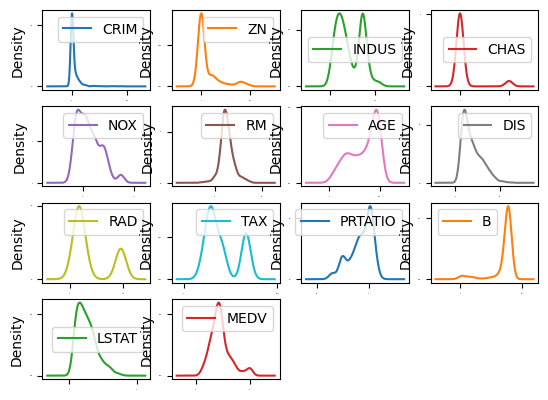

In [7]:
# 密度图
data.plot(kind='density',subplots=True,layout=(4,4),sharex=False,fontsize=1)
pyplot.show()

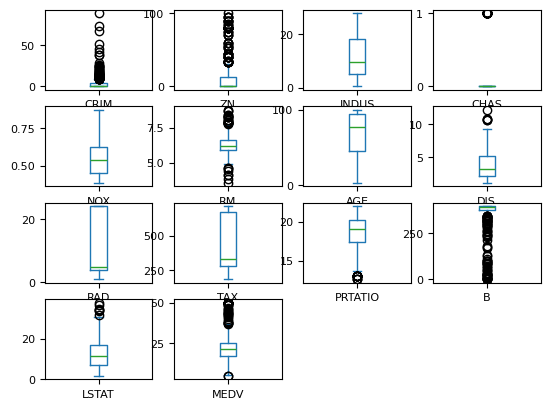

In [8]:
# 箱线图
data.plot(kind='box',subplots=True,layout=(4,4),sharex=False,sharey=False,fontsize=8)
pyplot.show()

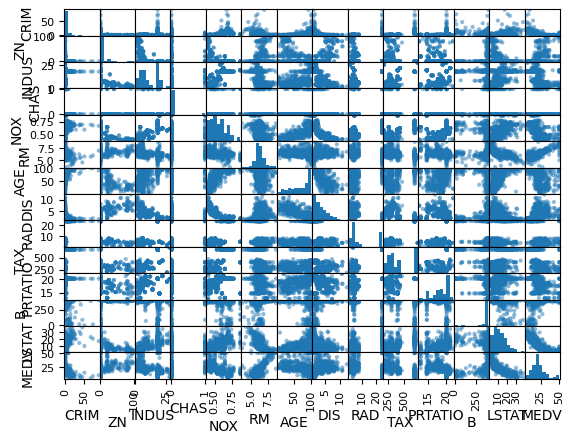

In [9]:
# 散点矩阵图
scatter_matrix(data)
pyplot.show()

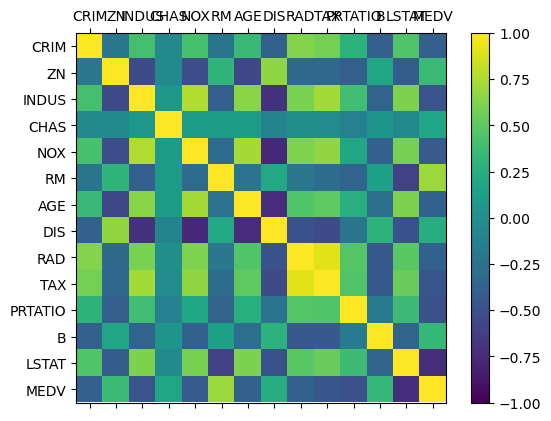

In [10]:
# 相关矩阵图
fig = pyplot.figure()
ax =fig.add_subplot(111)
cax =ax.matshow(data.corr(),vmin =-1,vmax=1,interpolation='none')
fig.colorbar(cax)
ticks =np.arange(0,14,1)
ax.set_xticks(ticks)
ax.set_yticks(ticks)
ax.set_xticklabels(names)
ax.set_yticklabels(names)
pyplot.show()

In [11]:
# 分离数据集
array =data.values
X =array[:,0:13]
Y =array[:,13]
validation_size =0.2
seed =7
X_train,X_validation,Y_train,Y_validation =train_test_split(X,Y,test_size=validation_size,random_state=seed)

In [12]:
# 4. 评估算法——评估标准
num_folds =10
seed=7
scoring ='neg_mean_squared_error'

# 评估算法- baseline
models ={}
models['LR']=LinearRegression()
models['LASSO']=Lasso()
models['EN']=ElasticNet()
models['KNN']=KNeighborsRegressor()
models['CART']=DecisionTreeRegressor()
models['SVM']=SVR()

In [13]:
# 评估算法
results =[]
for key in models:
    kfold =KFold(n_splits=num_folds,shuffle=True,random_state=seed)
    cv_result =cross_val_score(models[key],X_train,Y_train,cv=kfold,scoring=scoring)
    results.append(cv_result)
    print(f'{key}:{cv_result.mean():.2f}({cv_result.std():.2f})')

LR:-22.01(12.19)
LASSO:-27.11(13.17)
EN:-27.92(13.16)
KNN:-39.81(16.51)
CART:-25.30(16.94)
SVM:-67.82(32.80)


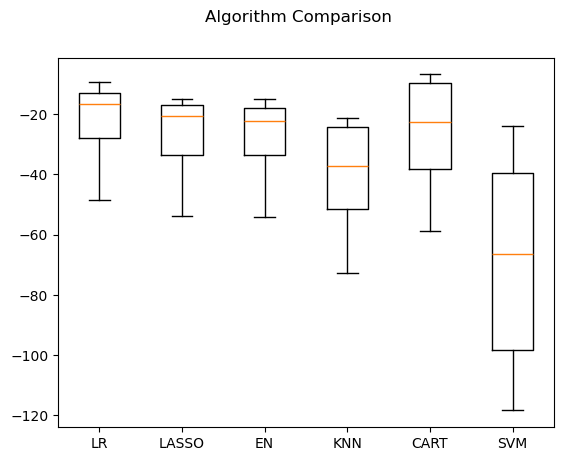

In [14]:
# 评估算法——箱线图(不同数量单位)
fig =pyplot.figure()
fig.suptitle('Algorithm Comparison')
ax =fig.add_subplot(111)
pyplot.boxplot(results)
ax.set_xticklabels(models.keys())
pyplot.show()

In [15]:
# 评估算法——正态化数据
pipelines={}
pipelines['ScalerLR']=Pipeline([('Scaler',StandardScaler()),('LR',LinearRegression())])
pipelines['SCalerLASSO']=Pipeline([('Scaler',StandardScaler()),('LASSO',Lasso())])
pipelines['ScalerEN']=Pipeline([('Scaler',StandardScaler()),('EN',ElasticNet())])
pipelines['ScalerKNN']=Pipeline([('Scaler',StandardScaler()),('KNN',KNeighborsRegressor())])
pipelines['ScalerCART']=Pipeline([('Scaler',StandardScaler()),('CART',DecisionTreeRegressor())])
pipelines['ScalerSVM']=Pipeline([('Scaler',StandardScaler()),('SVM',SVR())])
results=[]
for key in pipelines:
    kfold=KFold(n_splits=num_folds,shuffle=True,random_state=seed)
    cv_result=cross_val_score(pipelines[key],X_train,Y_train,cv=kfold,scoring=scoring)
    results.append(cv_result)
    print(f'{key}:{cv_result.mean():.2f}({cv_result.std():.2f})')

ScalerLR:-22.01(12.19)
SCalerLASSO:-27.21(12.12)
ScalerEN:-28.30(13.61)
ScalerKNN:-21.46(15.02)
ScalerCART:-23.73(15.79)
ScalerSVM:-29.57(18.05)


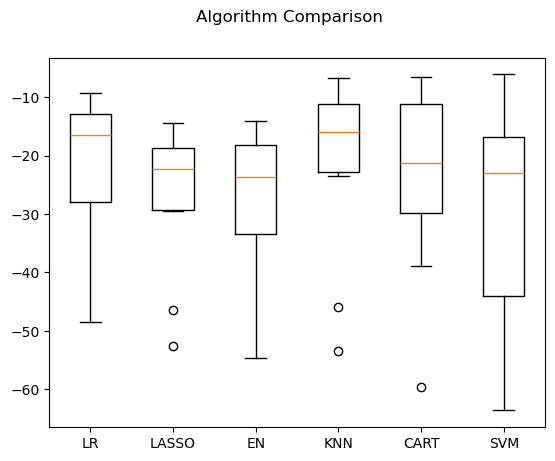

In [16]:
# 评估算法——箱线图
fig=pyplot.figure()
fig.suptitle('Algorithm Comparison')
ax=fig.add_subplot(111)
pyplot.boxplot(results)
ax.set_xticklabels(models.keys())
pyplot.show()

In [17]:
# 调参改善算法——KNN
scaler = StandardScaler().fit(X_train)
rescaledX=scaler.transform(X_train)
param_grid={'n_neighbors':[1,3,5,7,9,11,13,15,17,19,21]}
model=KNeighborsRegressor()
kfold=KFold(n_splits=num_folds,shuffle=True,random_state=seed)
grid=GridSearchCV(estimator=model,param_grid=param_grid,scoring=scoring,cv=kfold)
grid_result=grid.fit(X=rescaledX,y=Y_train)
print('最优：%s使用%s'%(grid_result.best_score_,grid_result.best_params_))
cv_results=zip(grid_result.cv_results_['mean_test_score'],grid_result.cv_results_['std_test_score'],grid_result.cv_results_['params'])
for mean,std,param in cv_results:
    print(f'{mean:.6f}({std:.6f})with{param}')

最优：-19.497828658536584使用{'n_neighbors': 1}
-19.497829(15.769847)with{'n_neighbors': 1}
-19.977984(13.803973)with{'n_neighbors': 3}
-21.270967(14.833544)with{'n_neighbors': 5}
-21.577292(14.952592)with{'n_neighbors': 7}
-21.001075(14.701297)with{'n_neighbors': 9}
-21.490306(14.866957)with{'n_neighbors': 11}
-21.268533(14.454969)with{'n_neighbors': 13}
-21.968092(14.209894)with{'n_neighbors': 15}
-22.739880(14.492752)with{'n_neighbors': 17}
-23.506901(14.903224)with{'n_neighbors': 19}
-24.240303(15.156565)with{'n_neighbors': 21}


In [18]:
# 集成算法
ensebles={}
ensebles['ScaledAB']=Pipeline([('Scaler',StandardScaler()),("AB",AdaBoostRegressor())])
ensebles['ScaledAB-KNN']=Pipeline([('Scaler',StandardScaler()),('ABKNN',AdaBoostRegressor(estimator=KNeighborsRegressor(n_neighbors=3)))])
ensebles['ScaledAB-LR']=Pipeline([('Scaler',StandardScaler()),('ABLR',AdaBoostRegressor(LinearRegression()))])
ensebles['ScaledRFR']=Pipeline([('Scaler',StandardScaler()),('RFR',RandomForestRegressor())])
ensebles['ScaledETR']=Pipeline([('Scaler',StandardScaler()),('ETR',ExtraTreesRegressor())])
ensebles['ScaledGBR']=Pipeline([('Scaler',StandardScaler()),('GBR',GradientBoostingRegressor())])
results=[]
for key in ensebles:
    kfold=KFold(n_splits=num_folds,shuffle=True,random_state=seed)
    cv_result=cross_val_score(ensebles[key],X_train,Y_train,cv=kfold,scoring=scoring)
    results.append(cv_result)
    print(f'{key}:{cv_result.mean()}({cv_result.std()})')

ScaledAB:-15.256496158757747(8.357908281776497)
ScaledAB-KNN:-16.153479403794037(11.232640479235817)
ScaledAB-LR:-24.045219416687836(8.400070255222776)
ScaledRFR:-13.099127954085366(10.261862354950425)
ScaledETR:-9.297650996097554(7.043679884164401)
ScaledGBR:-11.055367100746732(8.611922264890184)


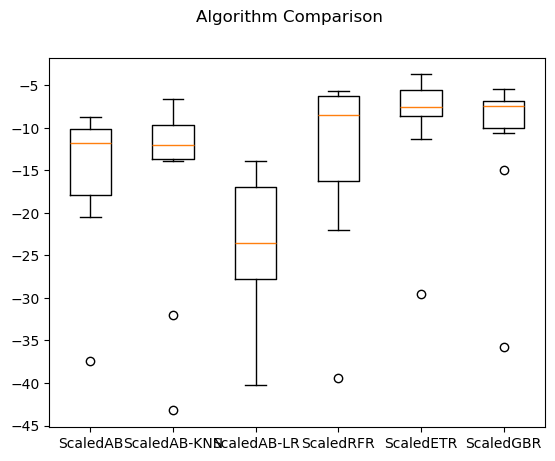

In [19]:
# 集成算法——箱线图
fig=pyplot.figure()
fig.suptitle('Algorithm Comparison')
ax=fig.add_subplot(111)
ax.boxplot(results)
ax.set_xticklabels(ensebles.keys())
pyplot.show()

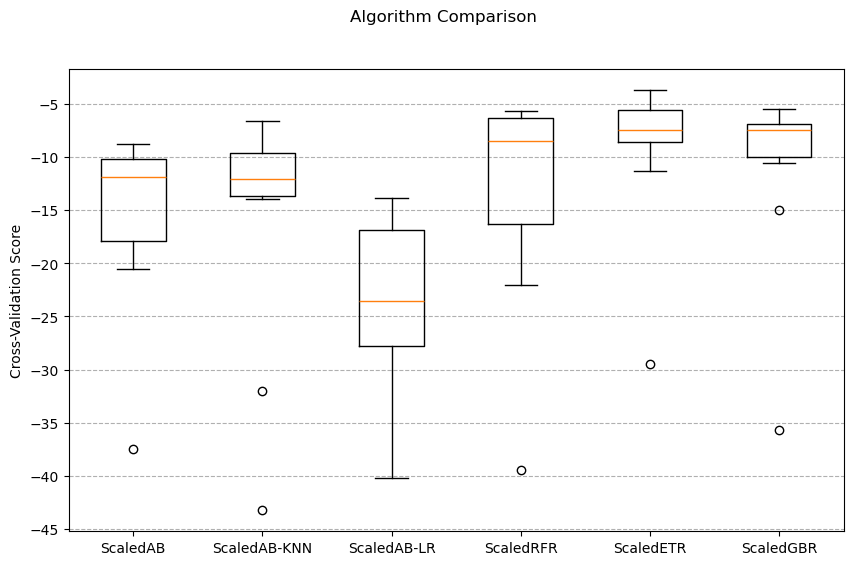

In [20]:
import matplotlib.pyplot as plt

# 1. 创建画布和坐标系（明确使用面向对象）
fig, ax = plt.subplots(figsize=(10, 6))  # 这是 add_subplot(111) 的简写，更常用

# 2. 绘制箱线图
ax.boxplot(results)  

# 3. 设置标题和标签（全部使用 ax. 或 fig.）
fig.suptitle('Algorithm Comparison')     # 总标题
ax.set_xticklabels(ensebles.keys())      # 替换 x 轴名称
ax.set_ylabel('Cross-Validation Score')  # 加 y 轴名称
ax.grid(axis='y', linestyle='--')        # 加网格线，便于看数值

# 4. 显示
plt.show()

In [21]:
# 集成算法GBM——调参
caler=StandardScaler().fit(X_train)
rescaledX=scaler.transform(X_train)
param_grid={'n_estimators':[600,620,640,660,680,700,720,740,760,780,800]}
model=GradientBoostingRegressor()
kfold=KFold(n_splits=num_folds,shuffle=True,random_state=seed)
grid=GridSearchCV(estimator=model,param_grid=param_grid,scoring=scoring,cv=kfold)
grid_result=grid.fit(X=rescaledX,y=Y_train)
print(f'最优：{grid_result.best_score_}使用{grid_result.best_params_}')

# 集成算法ET——调参
scaler=StandardScaler().fit(X_train)
rescaledX=scaler.transform(X_train)
param_grid={'n_estimators':[61,62,63,64,65,66,67,68,69,70]}
model=ExtraTreesRegressor()
kfold=KFold(n_splits=num_folds,shuffle=True,random_state=seed)
grid=GridSearchCV(estimator=model,param_grid=param_grid,scoring=scoring,cv=kfold)
grid_result=grid.fit(X=rescaledX,y=Y_train)
print(f'最优：{grid_result.best_score_}使用{grid_result.best_params_}')

最优：-10.346968258632765使用{'n_estimators': 600}
最优：-8.966013156867843使用{'n_estimators': 62}


In [22]:
# 训练模型
caler=StandardScaler().fit(X_train)
rescaledX=scaler.transform(X_train)
gbr=ExtraTreesRegressor(n_estimators=63)
gbr.fit(X=rescaledX,y=Y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",63
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, `

In [23]:
# 评估算法模型
rescaledX_validation=scaler.transform(X_validation)
predictions=gbr.predict(rescaledX_validation)
print(mean_squared_error(Y_validation,predictions))

14.870096211324032
